### Sel 1 - Import Library



In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from skimage import data, img_as_ubyte
from skimage.metrics import structural_similarity as ssim

print("Semua Library berhasil diimpor!")

Semua Library berhasil diimpor!


Silakan upload gambar dari komputer Anda.


Saving burung.jpg to burung.jpg
Nama gambar: burung.jpg
Ukuran gambar: (419, 731)
Gambar berhasil dibaca!


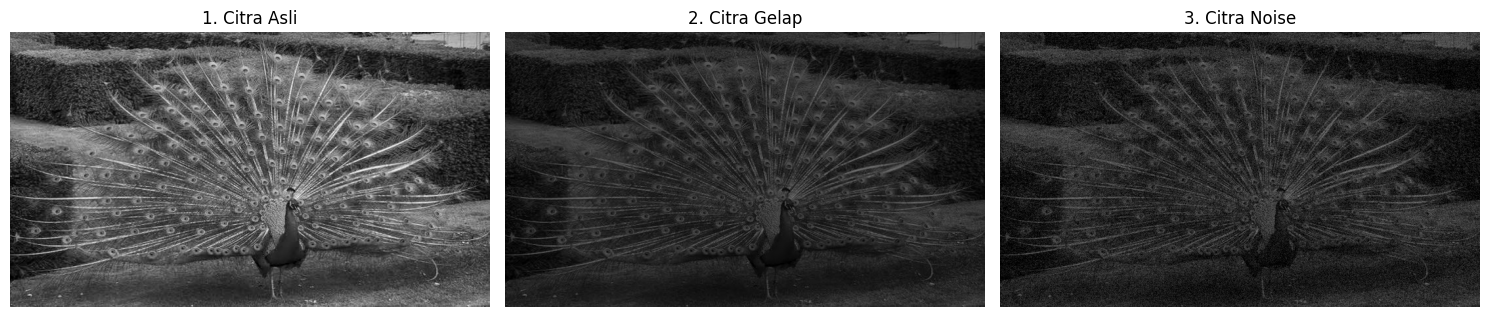

In [3]:
from google.colab import files
from PIL import Image
from io import BytesIO

# 1. Memilih dan mengunggah gambar
print("Silakan upload gambar dari komputer Anda.")
uploaded = files.upload()

if not uploaded:
  raise ValueError("Belum ada gambar yang diunggah.")

# 2. Membaca gambar yang dipilih
nama_file = next(iter(uploaded))
gambar = Image.open(BytesIO(uploaded[nama_file])).convert("RGB")

# Mengubah gambar berwarna menjadi grayscale
citra_asli = np.array(gambar.convert("L"),dtype=np.uint8)

print("Nama gambar:", nama_file)
print("Ukuran gambar:", citra_asli.shape)
print("Gambar berhasil dibaca!")

# 3. Membuat citra gelap dan Menambahkan Noise Gaussian
citra_gelap = np.clip(
    citra_asli.astype(np.float32) * 0.45, 0, 255
).astype(np.uint8)

# 4. Menambahkan noise Gaussian
np.random.seed(42)

noise = np.random.normal(loc=0,scale=12,size=citra_gelap.shape)

citra_noise = np.clip(
    citra_gelap.astype(np.float32) + noise, 0, 255
).astype(np.uint8)

# 5. Menampilkan perbandingan citra
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(citra_asli, cmap="gray", vmin=0, vmax=255)
plt.title("1. Citra Asli")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(citra_gelap, cmap="gray", vmin=0, vmax=255)
plt.title("2. Citra Gelap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(citra_noise, cmap="gray", vmin=0, vmax=255)
plt.title("3. Citra Noise")
plt.axis("off")

plt.tight_layout()
plt.show()

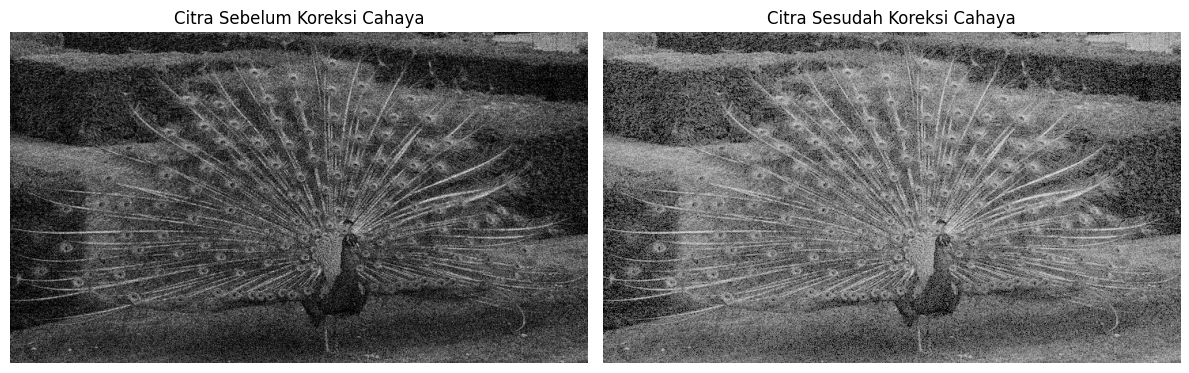

In [6]:
def sesuaikan_intensitas_cahaya(sumber_citra, faktor_gamma=0.6):
    data_normal = sumber_citra.astype(np.float32) / 255.0
    hasil_transformasi = np.power(data_normal, faktor_gamma) * 255.0
    return np.clip(hasil_transformasi, 0, 255).astype(np.uint8)

citra_hasil_gamma = sesuaikan_intensitas_cahaya(citra_noise, faktor_gamma=0.6)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(citra_noise, cmap="gray")
plt.title("Citra Sebelum Koreksi Cahaya")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(citra_hasil_gamma, cmap="gray")
plt.title("Citra Sesudah Koreksi Cahaya")
plt.axis("off")

plt.tight_layout()
plt.show()

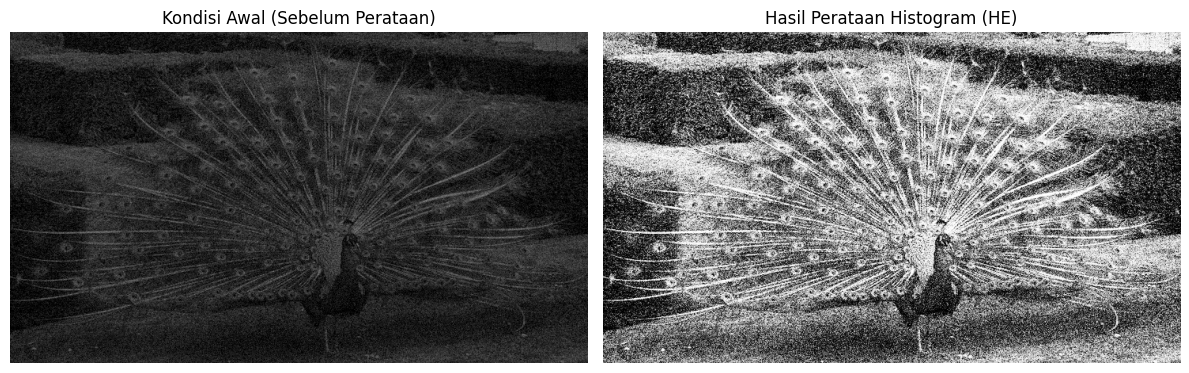

In [7]:
citra_hasil_rata = cv2.equalizeHist(citra_noise)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(citra_noise, cmap="gray", vmin=0, vmax=255)
plt.title("Kondisi Awal (Sebelum Perataan)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(citra_hasil_rata, cmap="gray", vmin=0, vmax=255)
plt.title("Hasil Perataan Histogram (HE)")
plt.axis("off")

plt.tight_layout()
plt.show()

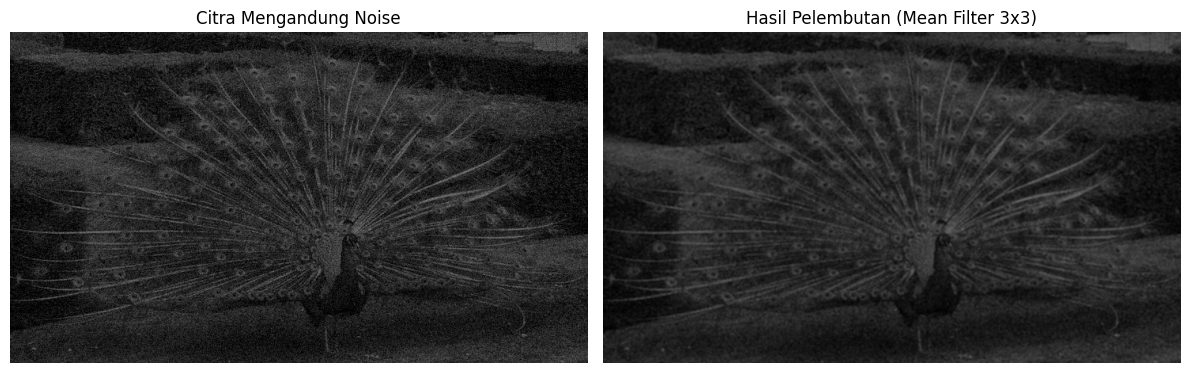

In [8]:
penapis_rerata = np.ones((3, 3), dtype=np.float32) / 9.0
citra_lembut = cv2.filter2D(citra_noise, -1, penapis_rerata)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(citra_noise, cmap="gray", vmin=0, vmax=255)
plt.title("Citra Mengandung Noise")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(citra_lembut, cmap="gray", vmin=0, vmax=255)
plt.title("Hasil Pelembutan (Mean Filter 3x3)")
plt.axis("off")

plt.tight_layout()
plt.show()

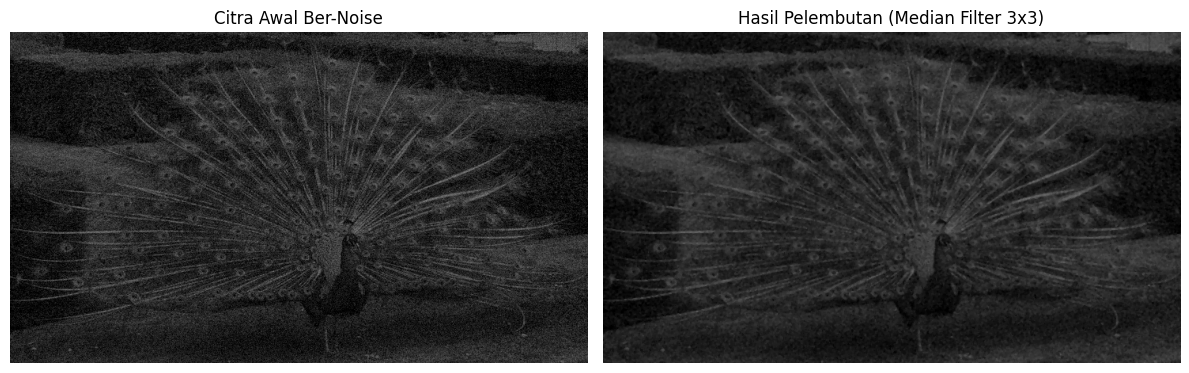

In [9]:
citra_median = cv2.medianBlur(citra_noise, 3)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(citra_noise, cmap="gray", vmin=0, vmax=255)
plt.title("Citra Awal Ber-Noise")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(citra_median, cmap="gray", vmin=0, vmax=255)
plt.title("Hasil Pelembutan (Median Filter 3x3)")
plt.axis("off")

plt.tight_layout()
plt.show()

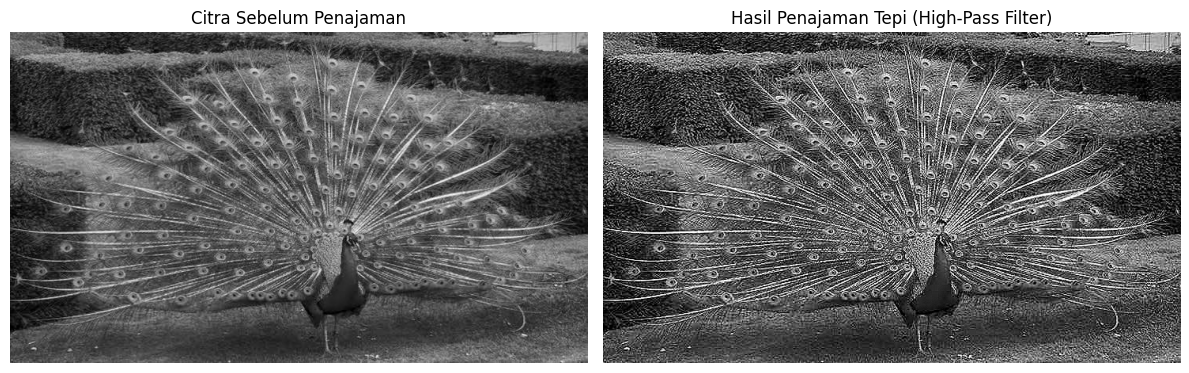

In [10]:
kernel_tajam = np.array([[0, -1, 0],
                         [-1, 5, -1],
                         [0, -1, 0]], dtype=np.float32)

citra_tajam = cv2.filter2D(citra_asli, -1, kernel_tajam)
citra_tajam = np.clip(citra_tajam, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(citra_asli, cmap="gray", vmin=0, vmax=255)
plt.title("Citra Sebelum Penajaman")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(citra_tajam, cmap="gray", vmin=0, vmax=255)
plt.title("Hasil Penajaman Tepi (High-Pass Filter)")
plt.axis("off")

plt.tight_layout()
plt.show()

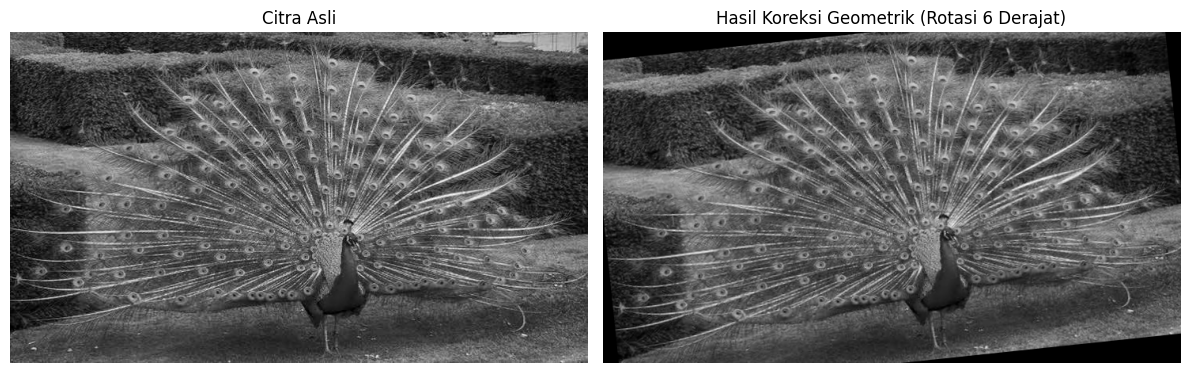

In [11]:
tinggi, lebar = citra_asli.shape
titik_pusat = (lebar // 2, tinggi // 2)

matriks_rotasi = cv2.getRotationMatrix2D(titik_pusat, 6, 1.0)
citra_rotasi = cv2.warpAffine(citra_asli, matriks_rotasi, (lebar, tinggi))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(citra_asli, cmap="gray", vmin=0, vmax=255)
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(citra_rotasi, cmap="gray", vmin=0, vmax=255)
plt.title("Hasil Koreksi Geometrik (Rotasi 6 Derajat)")
plt.axis("off")

plt.tight_layout()
plt.show()

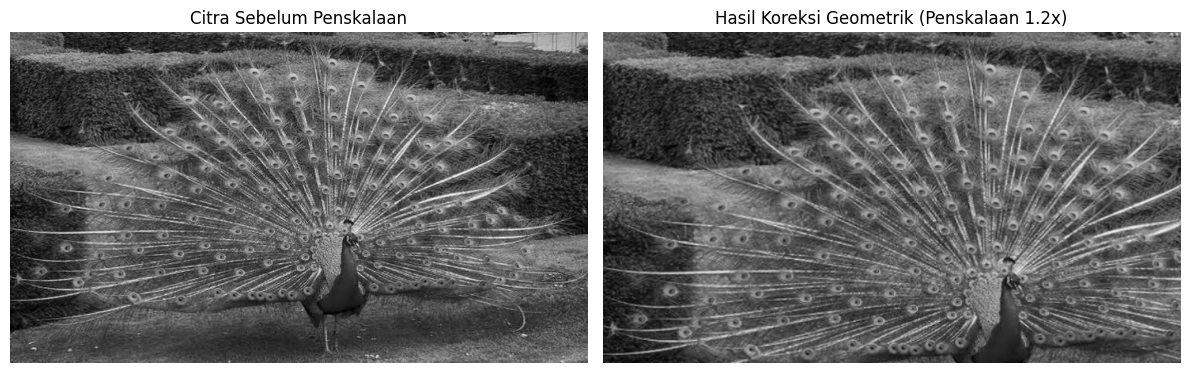

In [12]:
matriks_penskalaan = cv2.getRotationMatrix2D((0, 0), 0, 1.2)
citra_skala = cv2.warpAffine(citra_asli, matriks_penskalaan, (lebar, tinggi))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(citra_asli, cmap="gray", vmin=0, vmax=255)
plt.title("Citra Sebelum Penskalaan")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(citra_skala, cmap="gray", vmin=0, vmax=255)
plt.title("Hasil Koreksi Geometrik (Penskalaan 1.2x)")
plt.axis("off")

plt.tight_layout()
plt.show()

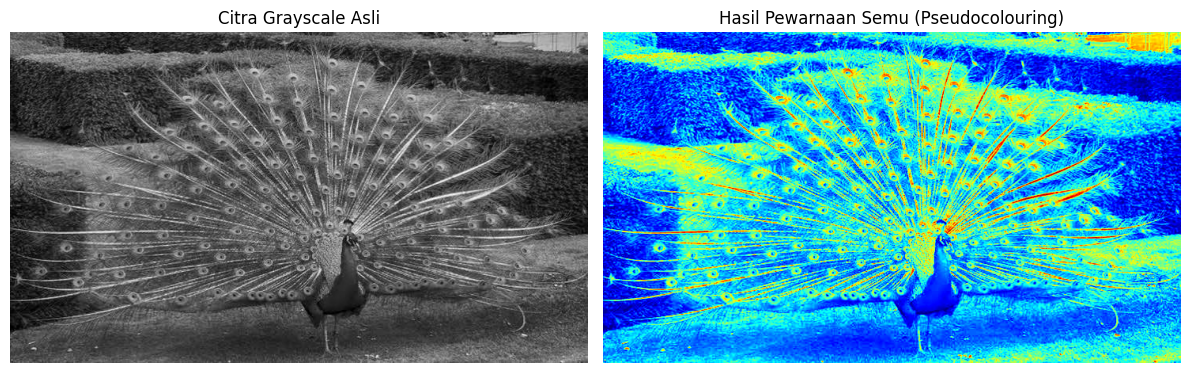

In [13]:
citra_warna_semu = cv2.applyColorMap(citra_asli, cv2.COLORMAP_JET)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(citra_asli, cmap="gray", vmin=0, vmax=255)
plt.title("Citra Grayscale Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(citra_warna_semu, cv2.COLOR_BGR2RGB))
plt.title("Hasil Pewarnaan Semu (Pseudocolouring)")
plt.axis("off")

plt.tight_layout()
plt.show()

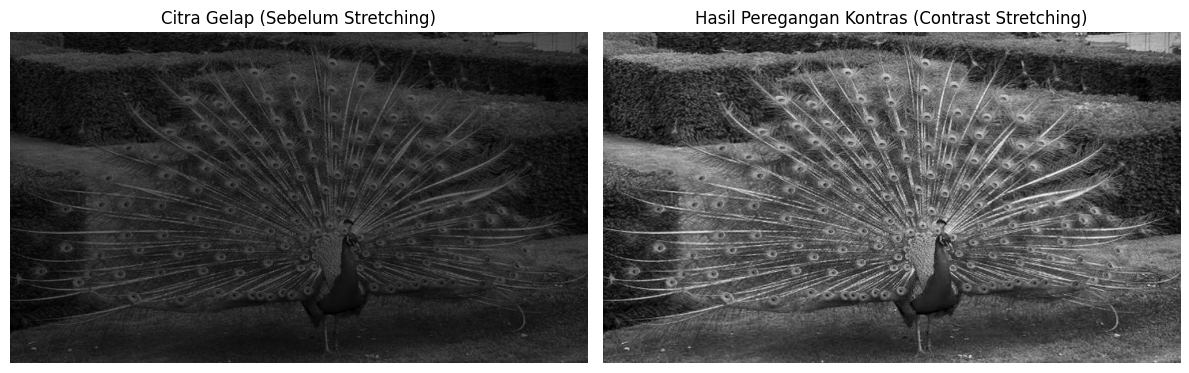

In [14]:
r_min = np.min(citra_gelap)
r_max = np.max(citra_gelap)

if r_max > r_min:
    citra_stretched = np.clip(
        ((citra_gelap.astype(np.float32) - r_min) / (r_max - r_min)) * 255.0,
        0, 255
    ).astype(np.uint8)
else:
    citra_stretched = citra_gelap.copy()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(citra_gelap, cmap="gray", vmin=0, vmax=255)
plt.title("Citra Gelap (Sebelum Stretching)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(citra_stretched, cmap="gray", vmin=0, vmax=255)
plt.title("Hasil Peregangan Kontras (Contrast Stretching)")
plt.axis("off")

plt.tight_layout()
plt.show()

Nilai Structural Similarity Index (SSIM): 0.9989


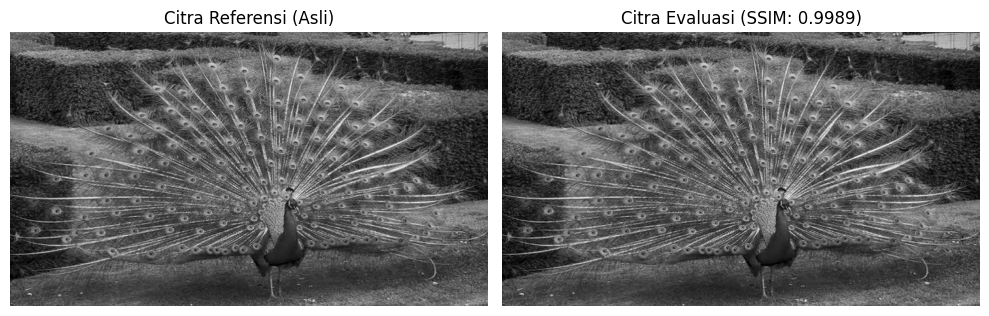

In [15]:
skor_ssim = ssim(citra_asli, citra_stretched)
print(f"Nilai Structural Similarity Index (SSIM): {skor_ssim:.4f}")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(citra_asli, cmap="gray", vmin=0, vmax=255)
plt.title("Citra Referensi (Asli)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(citra_stretched, cmap="gray", vmin=0, vmax=255)
plt.title(f"Citra Evaluasi (SSIM: {skor_ssim:.4f})")
plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
modul_terimplementasi = [
    "Koreksi Cahaya (Gamma)",
    "Perataan Histogram (HE)",
    "Pelembutan Mean Filter",
    "Pelembutan Median Filter",
    "Penajaman High-Pass Filter",
    "Transformasi Rotasi",
    "Transformasi Penskalaan",
    "Pewarnaan Semu (Pseudocolour)",
    "Peregangan Kontras (Contrast Stretching)",
    "Evaluasi Kualitas (SSIM)"
]

print(f"Total modul yang telah selesai: {len(modul_terimplementasi)}")
for i, modul in enumerate(modul_terimplementasi, 1):
    print(f"{i}. {modul} - OK")

Total modul yang telah selesai: 10
1. Koreksi Cahaya (Gamma) - OK
2. Perataan Histogram (HE) - OK
3. Pelembutan Mean Filter - OK
4. Pelembutan Median Filter - OK
5. Penajaman High-Pass Filter - OK
6. Transformasi Rotasi - OK
7. Transformasi Penskalaan - OK
8. Pewarnaan Semu (Pseudocolour) - OK
9. Peregangan Kontras (Contrast Stretching) - OK
10. Evaluasi Kualitas (SSIM) - OK


In [20]:
print("Semua modul tahapan pengolahan citra digital telah selesai dijalankan!")

Semua modul tahapan pengolahan citra digital telah selesai dijalankan!
